# 4. Graded outcomes: do they make striker differences easier to measure?

*Experiment on the `graded-outcome` branch. The pipelines and notebooks 1-3 are unchanged.*

Retention over expected scores each hold-up as kept (1) or lost (0). With about 13 hold-ups per striker that is very noisy: the intra-class correlation (ICC, the share of variance that is a real, repeatable striker difference) is about 0.3%. A **graded outcome** keeps more detail about *how* the hold-up went. This notebook builds four graded outcomes, learns the expected value of each given the situation (the same recipe as retention over expected), and compares how repeatable the striker differences are before (kept / lost) and after.

| Outcome | Definition |
| --- | --- |
| `retained` (before) | 1 if kept (or a foul won), 0 if lost |
| `survival` | share of the 3 s window his team kept the ball: 1 if kept, frames until the loss / 30 if lost (a defender winning it first = 0) |
| `epv` | SkillCorner EPV added by the hold-up (value added) |
| `tiered` | lost: 0.5 x survival (0 to 0.5); kept but EPV did not improve: 0.75; kept and EPV improved, or foul won: 1 |
| `blend` | retained and EPV added, each standardised, added together |

**Over expected.** For each outcome a ridge + boosted-tree model (the same pair used for expected EPV) predicts the outcome from the 13 features plus the starting EPV, out of fold by match. It is applied to the situation at first contact and at pass release. `oe_release` = outcome - expected at release (the retention-over-expected analogue); `oe_contact` = outcome - expected at contact (the duel analogue). For `retained` the pipeline's own classifier is used. Everything is compared on the **same 508 hold-ups** that have every outcome.

**How repeatability is judged** (all scale-free, so outcomes on different scales can be compared): ICC, the real between-striker spread relative to the noise in one hold-up, and the split-half correlation (each striker's hold-ups split at random in two; Spearman correlation across strikers of the two averages: near 0 means a striker's average in one half tells you nothing about the other half).

In [1]:
import sys
sys.path.insert(0, '../src')
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from holdup import graded, aggregate, model
from holdup.pipelines import run_training_pipeline, read_datasets
from holdup.paths import EVENTS_DIR, TRAINING_DIR
from holdup.plots import clean_axes, BLUE, ORANGE, GREEN, RED, GREY
pd.set_option('display.width', 170); pd.set_option('display.max_columns', 40)

events = read_datasets(EVENTS_DIR)
trained = run_training_pipeline(save=False)             # the model table (with out-of-fold calibrated xpass); nothing is overwritten
data = trained['table'].merge(events[['event_id', 'result', 'frames_to_loss', 'player', 'team_name']], on='event_id')
outcomes = graded.build_outcomes(data)
common = outcomes.drop(columns='event_id').notna().all(axis=1).to_numpy()
for c in graded.OUTCOMES: outcomes.loc[~common, c] = np.nan
print(len(data), 'hold-ups;', int(common.sum()), 'have every outcome and are used for the comparison')
outcomes.loc[common].describe().round(3).T

535 hold-ups; 508 have every outcome and are used for the comparison


,count,mean,std,min,25%,50%,75%,max
retained,508.0,0.415,0.493,0.000,0.000,0.000,1.000,1.000
survival,508.0,0.505,0.466,0.000,0.000,0.483,1.000,1.000
epv,508.0,-0.026,0.040,-0.239,-0.048,-0.038,-0.001,0.245
tiered,508.0,0.402,0.407,0.000,0.000,0.242,0.750,1.000
blend,508.0,0.000,1.729,-4.327,-1.364,-0.325,1.751,8.022


## 1. The graded outcomes

How the outcomes relate: `survival` and `tiered` mostly reorder the lost hold-ups (a loss after 2.9 s is no longer the same as a loss after 0.2 s); `epv` is on a different scale and also separates kept hold-ups that moved the attack on from those that did not.

lost hold-ups: 297; mean survival 0.153; share with zero survival (defender first or immediate loss) 70%
          retained  survival   epv  tiered  blend
retained      1.00      0.92  0.56    0.89   0.82
survival      0.92      1.00  0.55    0.97   0.76
epv           0.56      0.55  1.00    0.62   0.91
tiered        0.89      0.97  0.62    1.00   0.80
blend         0.82      0.76  0.91    0.80   1.00


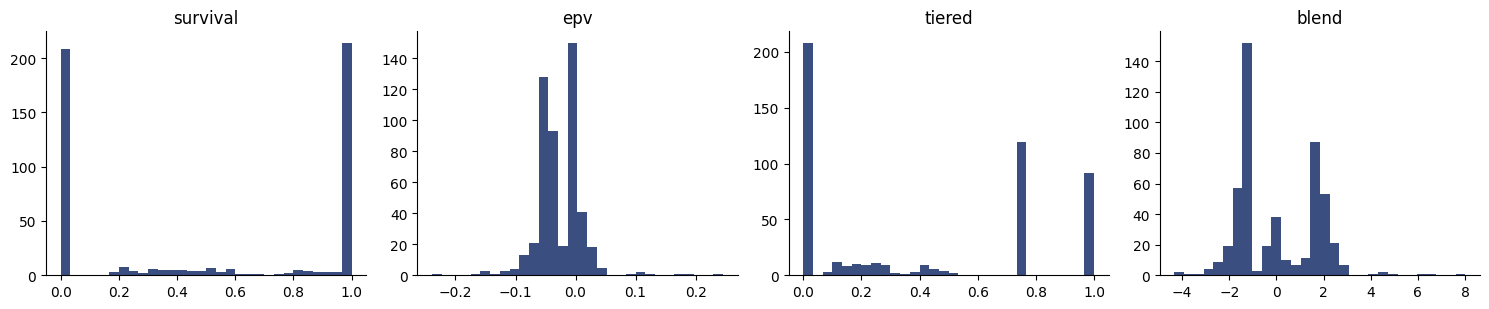

In [2]:
lost = common & (data.retained == 0).to_numpy()
print(f"lost hold-ups: {lost.sum()}; mean survival {outcomes.loc[lost, 'survival'].mean():.3f}; share with zero survival (defender first or immediate loss) {(outcomes.loc[lost, 'survival'] == 0).mean():.0%}")
print(outcomes.loc[common, list(graded.OUTCOMES)].corr(method='spearman').round(2))
fig, ax = plt.subplots(1, 4, figsize=(15, 3.2))
for a, c in zip(ax, ['survival', 'epv', 'tiered', 'blend']):
    a.hist(outcomes.loc[common, c], bins=30, color=BLUE); a.set_title(c); clean_axes(a)
plt.tight_layout(); plt.show()

## 2. Over-expected scores

Out-of-fold expected outcomes for each graded outcome. `r2_out_of_fold` = how much of the variation in the outcome the situation explains out of fold (for `retained` it is the pipeline classifier).

In [3]:
OE, rows = {}, []
for name in graded.OUTCOMES:
    oe = graded.over_expected(data, outcomes, name, production_classifier=(name == 'retained'))
    OE[name] = oe.merge(data[['event_id', 'player', 'team_name']], on='event_id').assign(key=lambda x: x.player + ' | ' + x.team_name)
    y_, e_ = oe.outcome, oe.expected_contact
    rows.append(dict(outcome=name, hold_ups=len(oe), mean=y_.mean(), sd=y_.std(), r2_out_of_fold=1 - ((y_ - e_) ** 2).sum() / ((y_ - y_.mean()) ** 2).sum()))
pd.DataFrame(rows).set_index('outcome').round(3)

,hold_ups,mean,sd,r2_out_of_fold
outcome,,,,
retained,508,0.415,0.493,0.202
survival,508,0.505,0.466,0.389
epv,508,-0.026,0.040,0.166
tiered,508,0.402,0.407,0.320
blend,508,0.000,1.729,0.200


## 3. Before vs after: how repeatable are the striker differences?

`release` = the retention-over-expected analogue (set-up and duel together); `contact` = the duel analogue. Higher ICC, real spread over noise and split-half are better. Interval width is in units of one hold-up's sd, so a *wider* number here is not worse: it means the model pulls the striker less towards the league mean because it finds more real spread.

In [4]:
rows = []
for name in graded.OUTCOMES:
    for kind in ('release', 'contact'):
        r = graded.reliability(OE[name], 'oe_' + kind); r.update(outcome=name, kind=kind); rows.append(r)
R = pd.DataFrame(rows).set_index(['outcome', 'kind'])
R.to_csv(TRAINING_DIR / 'graded_comparison.csv')
R[['hold_ups', 'rated', 'sd_one_holdup', 'real_sd_median', 'real_sd_p95', 'real_sd_over_noise', 'icc_median', 'icc_p95', 'interval_width_in_holdup_sd', 'excluding_league', 'split_half_mean', 'split_half_p5', 'split_half_p95']].round(3)

hold_ups  rated  sd_one_holdup  real_sd_median  real_sd_p95  real_sd_over_noise  icc_median  icc_p95  interval_width_in_holdup_sd  excluding_league  \
outcome  kind                                                                                                                                                           
retained release       508     21          0.466           0.025        0.073               0.055       0.003    0.024                        0.240                 0   
         contact       508     21          0.447           0.023        0.067               0.051       0.003    0.022                        0.225                 0   
survival release       508     21          0.379           0.025        0.070               0.067       0.004    0.033                        0.278                 0   
         contact       508     21          0.367           0.024        0.067               0.066       0.004    0.032                        0.275                 0   
epv      release       508     21          0.036           0.006        0.011               0.167       0.027    0.087                        0.494                 0   
         contact       508     21          0.036           0.005        0.010               0.141       0.020    0.076                        0.450                 0   
tiered   release       508     21          0.349           0.029        0.074               0.084       0.007    0.043                        0.327                 0   
         contact       508     21          0.338           0.026        0.068               0.076       0.006    0.038                        0.308                 0   
blend    release       508     21          1.575           0.154        0.368               0.098       0.010    0.052                        0.364                 0   
         contact       508     21          1.542           0.132        0.331               0.086       0.007    0.044                        0.333                 0   

                  split_half_mean  split_half_p5  split_half_p95  
outcome  kind                                                     
retained release            0.056         -0.218           0.342  
         contact            0.012         -0.270           0.312  
survival release            0.087         -0.146           0.354  
         contact            0.069         -0.177           0.330  
epv      release            0.263          0.018           0.517  
         contact            0.248         -0.008           0.511  
tiered   release            0.167         -0.114           0.435  
         contact            0.141         -0.137           0.448  
blend    release            0.185         -0.049           0.447  
         contact            0.171         -0.090           0.446

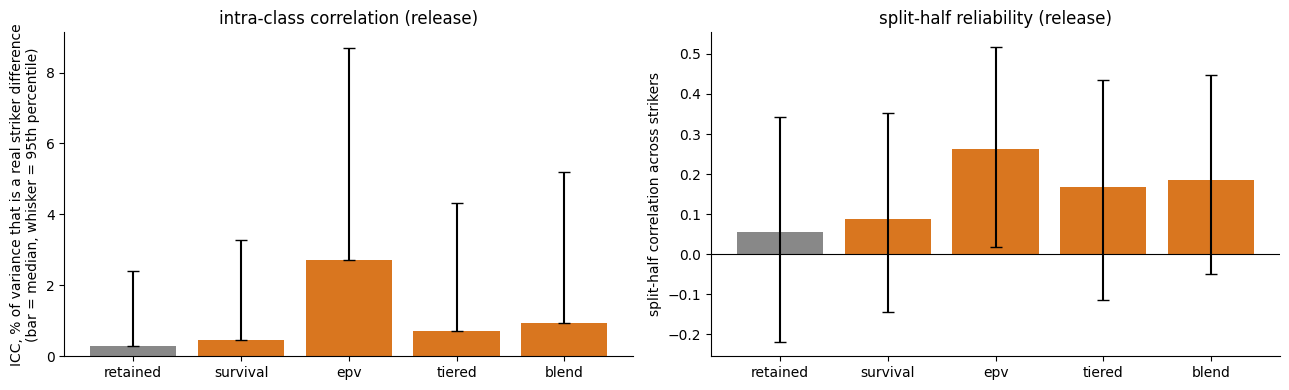

In [5]:
rel = R.xs('release', level='kind'); names = list(rel.index)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
cols = [GREY] + [ORANGE] * (len(names) - 1)
ax[0].bar(names, rel.icc_median * 100, color=cols); ax[0].errorbar(range(len(names)), rel.icc_median * 100, yerr=[np.zeros(len(names)), (rel.icc_p95 - rel.icc_median) * 100], fmt='none', ecolor='k', capsize=4)
ax[0].set_ylabel('ICC, % of variance that is a real striker difference\n(bar = median, whisker = 95th percentile)'); ax[0].set_title('intra-class correlation (release)')
ax[1].bar(names, rel.split_half_mean, color=cols); ax[1].errorbar(range(len(names)), rel.split_half_mean, yerr=[rel.split_half_mean - rel.split_half_p5, rel.split_half_p95 - rel.split_half_mean], fmt='none', ecolor='k', capsize=4)
ax[1].axhline(0, c='k', lw=.8); ax[1].set_ylabel('split-half correlation across strikers'); ax[1].set_title('split-half reliability (release)')
for a in ax: clean_axes(a)
plt.tight_layout(); plt.show()

## 4. Is the extra signal the striker, or the team and the pitch position?

EPV in particular depends heavily on where on the pitch the hold-up happens and on the team's style, which the striker does not fully control. If strikers on the same team look alike, a high ICC could be a team effect. The test: subtract each team's average from every score and repeat. If the ICC survives it, the difference is within teams (between strikers of the same team).

In [6]:
rows = []
for name in graded.OUTCOMES:
    s = OE[name].copy(); col = 'oe_release'
    team_icc = aggregate.between_spread(s.assign(key=s.team_name), col)['icc_median']
    s['demeaned'] = s[col] - s.groupby('team_name')[col].transform('mean')
    rows.append(dict(outcome=name, icc_by_striker=aggregate.between_spread(s, col)['icc_median'], icc_by_team=team_icc,
                     icc_by_striker_after_removing_team_mean=aggregate.between_spread(s, 'demeaned')['icc_median']))
pd.DataFrame(rows).set_index('outcome').round(4)

,icc_by_striker,icc_by_team,icc_by_striker_after_removing_team_mean
outcome,,,
retained,0.0030,0.0025,0.0020
survival,0.0045,0.0049,0.0022
epv,0.0272,0.0266,0.0031
tiered,0.0071,0.0053,0.0029
blend,0.0095,0.0083,0.0029


## 5. Do the intervals get any narrower?

The shrunk 90% interval of the best graded outcome next to retention over expected, for the rated strikers, in **standardised units** (divided by the sd of one hold-up) so the two are comparable.

graded outcome with the highest ICC: epv


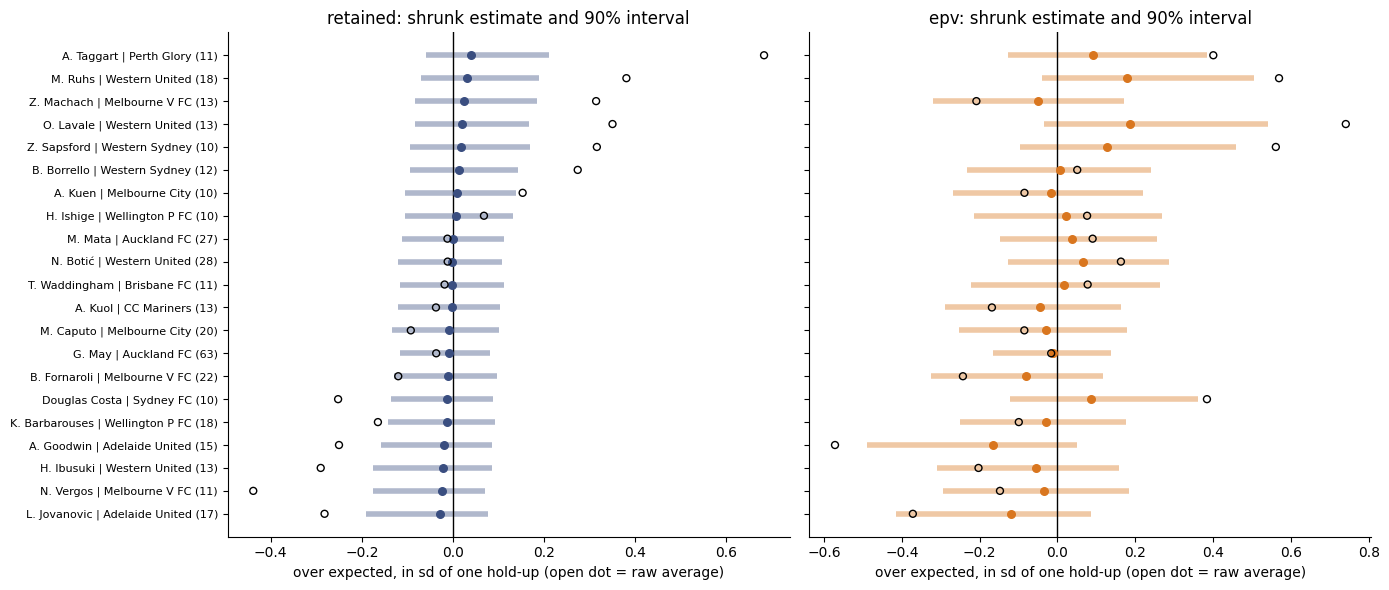

In [7]:
best = R.xs('release', level='kind').icc_median.drop('retained').idxmax()
print('graded outcome with the highest ICC:', best)
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
order = None
for ax, name in zip(axes, ['retained', best]):
    d = OE[name].dropna(subset=['oe_release']); sd = d.oe_release.std()
    t, mu, _ = aggregate.shrink_metric(d, 'oe_release', 10, draws=2000); t = t[t.rated].copy()
    if order is None: order = t.sort_values('shrunk').index
    t = t.reindex(order); y = np.arange(len(t)); colour = BLUE if name == 'retained' else ORANGE
    ax.hlines(y, t.lo / sd, t.hi / sd, color=colour, lw=4, alpha=.4); ax.scatter(t.shrunk / sd, y, c=colour, zorder=3, s=30); ax.scatter(t.raw / sd, y, facecolors='none', edgecolors='k', zorder=3, s=25)
    ax.axvline(mu / sd, c='k', lw=1); ax.set_title(f'{name}: shrunk estimate and 90% interval'); ax.set_xlabel('over expected, in sd of one hold-up (open dot = raw average)'); clean_axes(ax)
axes[0].set_yticks(y); axes[0].set_yticklabels([k + f' ({int(n)})' for k, n in zip(t.index, t.n)], fontsize=8)
plt.tight_layout(); plt.show()

## 6. Controlling for team and pitch position inside the model

Section 4 subtracted team means *after* the fact. A cleaner test puts the context **into the expected-outcome model**: team indicators plus where the hold-up happens (striker x, his absolute y and the line height at contact), at both release and contact. The over-expected score then only credits the striker for what is beyond his team's usual result and his position on the pitch.

One limit: in this data every striker played for a single team (56 strikers, 56 striker-team pairs), so team terms and striker terms cannot be fully separated. Controlling for team removes some real striker signal along with the team effect. If the ICC survives, the signal is within-team; if it vanishes, the data cannot tell the two apart.

In [8]:
events_ctx = events.set_index('event_id')
ctx = pd.get_dummies(data.team_name, prefix='team').astype(float)
ctx['striker_x_contact'] = data.event_id.map(events_ctx.striker_x_contact).to_numpy()
ctx['striker_y_abs'] = data.event_id.map(events_ctx.striker_y_contact).abs().to_numpy()
ctx['line_x_contact'] = data.event_id.map(events_ctx.line_x_contact).to_numpy()
print(data.player.nunique(), 'strikers and', (data.player + data.team_name).nunique(), 'striker-team pairs')
rows = []
for name in graded.OUTCOMES:
    oe = graded.over_expected(data, outcomes, name, production_classifier=(name == 'retained'), context=ctx)
    s = oe.merge(data[['event_id', 'player', 'team_name']], on='event_id').assign(key=lambda x: x.player + ' | ' + x.team_name)
    r = graded.reliability(s, 'oe_release'); y_ = oe.outcome
    rows.append(dict(outcome=name, r2_with_context=1 - ((y_ - oe.expected_contact) ** 2).sum() / ((y_ - y_.mean()) ** 2).sum(), icc_without_context=R.loc[(name, 'release'), 'icc_median'], icc_with_context=r['icc_median'], icc_p95_with_context=r['icc_p95'],
                     split_half_without=R.loc[(name, 'release'), 'split_half_mean'], split_half_with=r['split_half_mean'], excluding_league=r['excluding_league']))
CTX = pd.DataFrame(rows).set_index('outcome'); CTX.to_csv(TRAINING_DIR / 'graded_comparison_context.csv'); CTX.round(4)

56 strikers and 56 striker-team pairs


,r2_with_context,icc_without_context,icc_with_context,icc_p95_with_context,split_half_without,split_half_with,excluding_league
outcome,,,,,,,
retained,0.1830,0.0030,0.0035,0.0293,0.0565,0.0418,0
survival,0.3796,0.0045,0.0042,0.0328,0.0867,-0.0120,0
epv,0.1769,0.0272,0.0045,0.0377,0.2634,0.0416,0
tiered,0.3153,0.0071,0.0056,0.0391,0.1668,0.0997,0
blend,0.1928,0.0095,0.0053,0.0397,0.1851,0.0558,0


## 7. Reading the result

* The table in section 3 is the comparison: the ICC and split-half of `retained` (the before) against each graded outcome (the after).
* Judge each outcome by repeatability, not by how small its single-hold-up sd is: an outcome with less noise per hold-up only helps if the extra detail is signal about the striker.
* Section 4 says how much of any gain is a striker difference rather than a team difference. Section 5 shows what that means for the interval charts.